In [11]:
import pandas as pd
from datetime import datetime
from zoneinfo import ZoneInfo

# Tiempos de Viaje para ODs de Interés [DRAFT]

Recolectamos tiempos de viaje y distancias recorridas entre los orígenes y destinos definidos para las líneas BRT. Los datos fueron recolectados entre el 8 y el 18 de mayo, cada 15 minutos. Durante la recolección, se perdieron algunas consultas por problemas técnicos que estamos trabajando en resolver.
Luego de recolectar los datos, agrupamos los tiempos y distancias a nivel horario y calculamos la media para ambas variables. Finalmente, generamos los gráficos que se muestran a continuación.

Observaciones:

- Para algunas horas del día, el par Ciudad Vieja/Zona América tiene distancias de viaje de 40 km. En Google, notamos que para ciertas horas del día puede ser más conveniente tomar caminos significatiamente más largos. (nota: sería bueno confirmar con alguien del lugar.)
- Comparamos los tiempos de viaje contra los de Google y nuestra media se encuentra entre el tiempo de viaje mínimo y máximo informado por ellos. (nota: confirmar con alguien del lugar)

## Próximos Pasos
- Les interesa seguir recolectando estos datos? 
- Quisieran agregar más ODs de interés?

In [12]:
def from_tztotz(tz1, time1, tz2):
    '''
    Convert a timestamp from one timezone to another timezone.
    
    Parameters:
    -----------
    tz1 : str
        Source timezone name (e.g., 'UTC', 'America/New_York', 'Asia/Tokyo').
        Must be a valid timezone name from the IANA Time Zone Database.
    
    time1 : str
        Timestamp string in the format 'YYYYMMDDhhmm' (e.g., '202309241530' for
        September 24, 2023, 3:30 PM).
    
    tz2 : str
        see tz1
    
    Returns:
    --------
    str
        Timestamp string in the target timezone, formatted as 'YYYYMMDDhhmm'.
    '''
    dt = datetime.strptime(time1, '%Y%m%d%H%M')
    dt_tz1 = dt.replace(tzinfo=ZoneInfo(tz1))
    dt_tz2 = dt_tz1.astimezone(ZoneInfo(tz2))
    year, month, day, hour, minute = dt_tz2.year, dt_tz2.month, dt_tz2.day, dt_tz2.hour, dt_tz2.minute
    return f'{year}{month:02d}{day:02d}{hour:02d}{minute:02d}'

In [108]:
import os
import glob

results_path = '/home/sol/gitrepo/montevideo-brt/results/'
files = glob.glob(os.path.join(results_path, '*.csv'))

df_combined = pd.DataFrame()

for file in files:
    # Extract year, month, day, hour, minute from filename
    basename = os.path.basename(file).replace('.csv', '')
    datetime_str = basename[-12:]
    datetime_str = from_tztotz('UTC', datetime_str, 'America/Montevideo')
    year = int(datetime_str[0:4])
    month = int(datetime_str[4:6])
    day = int(datetime_str[6:8])
    hour = int(datetime_str[8:10])
    minute = int(datetime_str[10:12])
    date = f'{year}-{month:02d}-{day:02d}'
    df_file = pd.read_csv(file)

    # Get tt and dist column names
    tt_col = [c for c in df_file.columns if c.startswith('tt_')][0]
    dist_col = [c for c in df_file.columns if c.startswith('dist_')][0]
    flipped_tt_col = [c for c in df_file.columns if c.startswith('flipped_tt_')][0]
    flipped_dist_col = [c for c in df_file.columns if c.startswith('flipped_dist_')][0]

    for row_i in range(2):
        row = df_file.iloc[row_i]
        record = {
            'od_id': row['od_id'],
            'od_name': row['od_name'],
            'origin': row['origin'],
            'destination': row['destination'],
            'tt': row[tt_col],
            'dist': row[dist_col],
            'year': year,
            'month': month,
            'day': day,
            'hour': hour,
            'minute': minute,
            'date': date,
            'datetime': datetime_str
        }
        df_combined = pd.concat([df_combined, pd.DataFrame([record])], ignore_index=True)

        # Flipped direction
        flipped_record = {
            'od_id': row['od_id'],
            'od_name': row['od_name'],
            'origin': row['destination'],
            'destination': row['origin'],
            'tt': row[flipped_tt_col],
            'dist': row[flipped_dist_col],
            'year': year,
            'month': month,
            'day': day,
            'hour': hour,
            'minute': minute,
            'date': date,
            'datetime': datetime_str
        }
        df_combined = pd.concat([df_combined, pd.DataFrame([flipped_record])], ignore_index=True)

print(df_combined.shape)
df_combined['time'] = pd.to_datetime(df_combined['hour'].astype('str') + ':' + df_combined['minute'].astype('str'), format='%H:%M')
df_combined['tt'] = df_combined['tt']/60  # Convert tt from seconds to minutes
df_combined['dist'] = df_combined['dist']/1000  # Convert dist from meters to kilometers
df_combined['weekday'] = pd.to_datetime(df_combined['date']).dt.day_name()
df_combined.sort_values(by=['od_id', 'datetime'], inplace=True)

(2628, 13)


In [100]:
import itertools
hour_minute_combinations = list(itertools.product(range(24), [0, 15, 30, 45]))

In [122]:
def create_plots(od_, colors, variable, title_prefix, ylabel):
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, origin in enumerate(od_['origin'].unique()):
        df_plot = od_[od_['origin'] == origin].copy()
        mean_profile = df_plot.groupby(['hour'])[variable].mean()
        mean_profile = mean_profile.reindex(range(24), fill_value=np.nan)
        origin = df_plot['origin'].iloc[0]
        destination = df_plot['destination'].iloc[0]
        for date in df_plot['date'].unique():
            df_date = df_plot[df_plot['date'] == date]
            mean_ = df_date.groupby('hour')[variable].mean()
            mean_ = mean_.reindex(range(24), fill_value=np.nan)

            ax.plot(
                mean_.index,
                mean_,
                color= colors[i],
                alpha=0.25,
                linewidth=1,
            )

        # Plot average
        ax.plot(
            mean_profile.index,
            mean_profile.values,
            color=colors[i],
            linewidth=3,
            label=f"Promedio| {origin} - {destination}"
        )

    # # Formatting
    ax.set_xlabel("Hora del día")
    ax.set_ylabel(ylabel)
    ax.set_title(f"{title_prefix} | {od_['od_name'].iloc[0]}")
    ax.set_xticks(range(0, 24))
    ax.grid(alpha=0.2)

    plt.legend()
    plt.tight_layout()
    plt.show()

# Weekdays

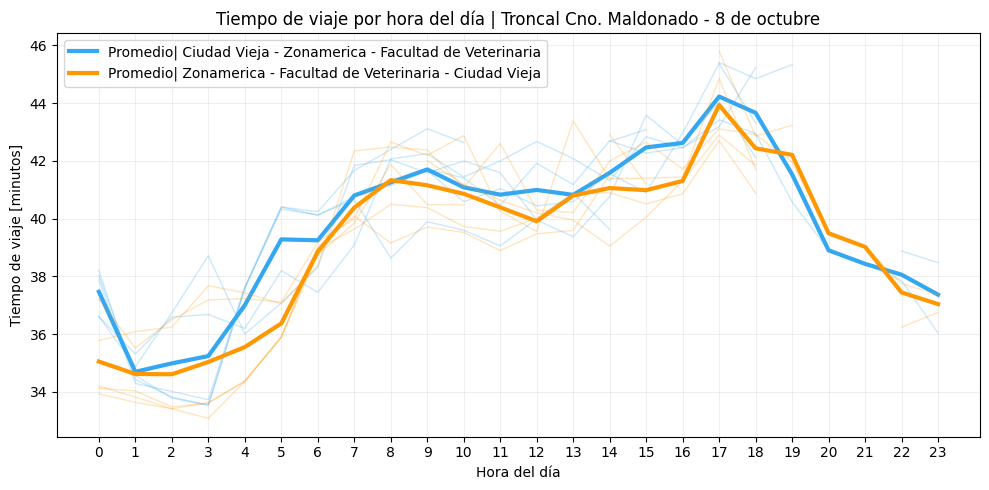

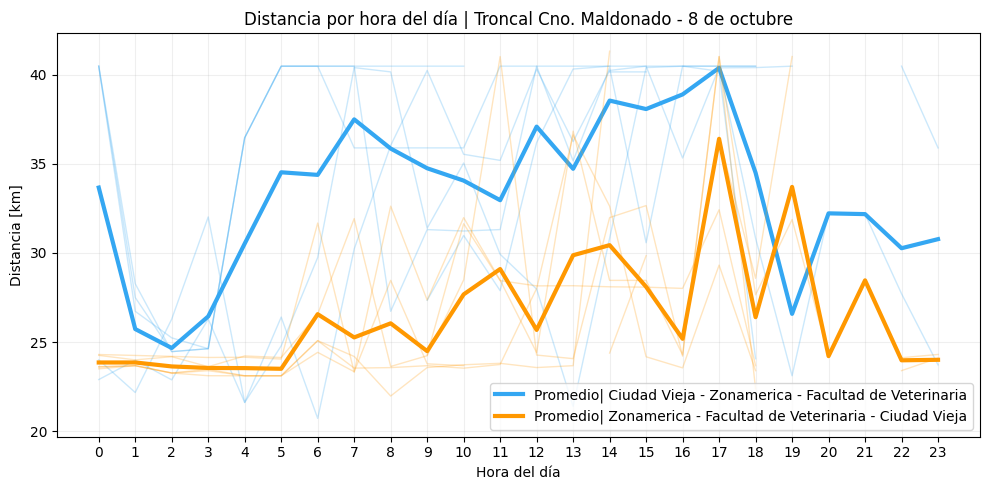

In [127]:
ylabel = "Tiempo de viaje [minutos]"
title_prefix = "Tiempo de viaje por hora del día"
od_ = df_combined[(df_combined['od_id'] == 0)&(df_combined['weekday'].isin(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']))].copy()
create_plots(od_, colors, 'tt', title_prefix, ylabel)
ylabel = "Distancia [km]"
title_prefix = "Distancia por hora del día"
create_plots(od_, colors, 'dist', title_prefix, ylabel)

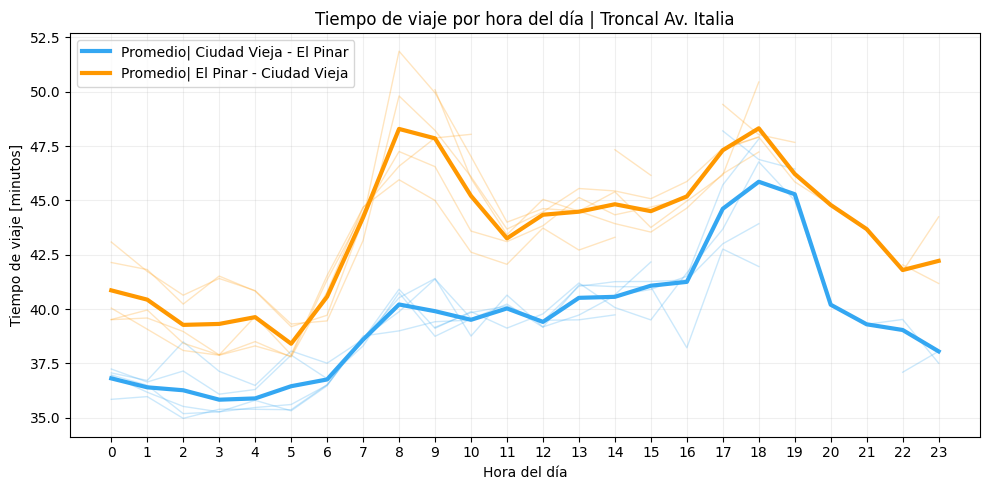

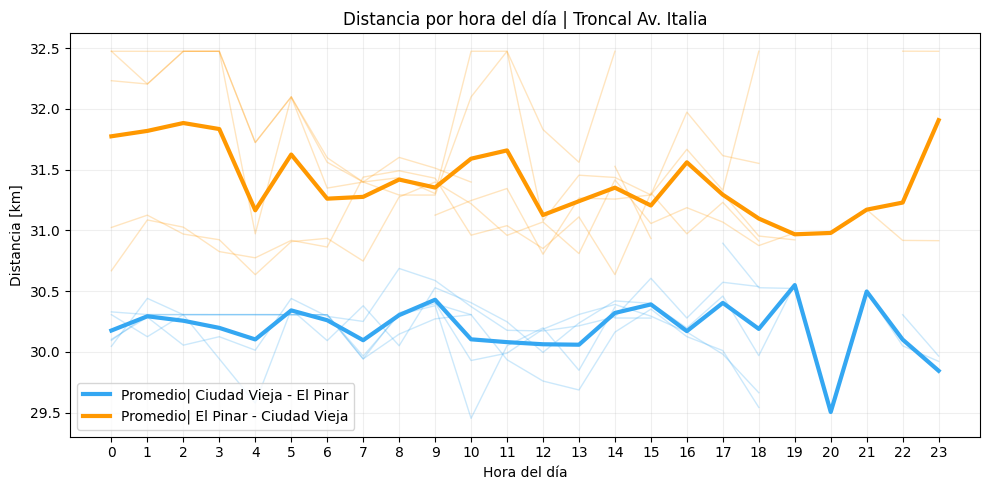

In [129]:
ylabel = "Tiempo de viaje [minutos]"
title_prefix = "Tiempo de viaje por hora del día"
od_ = df_combined[(df_combined['od_id'] == 1)&(df_combined['weekday'].isin(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']))].copy()
create_plots(od_, colors, 'tt', title_prefix, ylabel)

ylabel = "Distancia [km]"
title_prefix = "Distancia por hora del día"
create_plots(od_, colors, 'dist', title_prefix, ylabel)